# Mantenimiento predictivo, semana 3: modelo avanzado, confiabilidad y política de mantenimiento

Punto de partida: la serie cruda de 13 canales horarios (semana 1, `week1_predictive_maintenance_serie_cruda.ipynb`) y el mejor modelo de la semana 2 (`models/week2_best.pt`: TCN, L = 24 h, sobremuestreo de ventanas pre-falla, hiperparámetros de Optuna). El código reutilizable está en `pm_dl.py` (tensor, arquitecturas, entrenamiento, métricas) y `pm_week3.py` (Transformer, incertidumbre, gradientes integrados, simulación de políticas).

**Protocolo contra fuga de información.** Todas las decisiones (arquitectura final, temperatura, umbral de alerta, periodo de reemplazo por calendario) se toman con entrenamiento y validación y se guardan en `data/processed/week3_decisions.json`. El conjunto de prueba se abre **una sola vez**, en la sección *Evaluación final en prueba*, que lee ese archivo y no cambia ninguna decisión.

Las redes de esta semana se guardan en `models/week3/`. Si existen se cargan; si no, se entrenan con exactamente los mismos argumentos (`python train_week3.py` llena ese caché de antemano). Borrar la carpeta reentrena todo.

In [1]:
import os, sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, f1_score

sys.path.insert(0, '.')
from pm_dl import *
from pm_week3 import *

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
FIG_DIR = os.path.join('figures', 'week3'); os.makedirs(FIG_DIR, exist_ok=True)
DECISIONS = os.path.join(OUT_DIR, 'week3_decisions.json')

telemetry, errors, maint, failures, machines = load_raw()
grid = build_hourly_channels(telemetry, errors, maint)
tcn_w2, ck = load_week2_best()                       # week-2 model and its train-only normalisation
store = SequenceStore(grid, machines, ck['norm_stats'])
TR = SplitData(load_split('train', machines), store, ck['age_stats'])
VA = SplitData(load_split('validation', machines), store, ck['age_stats'])
val_meta = VA.df[['machineID', 'datetime']]
val_es_idx = np.arange(0, len(VA), 3)                 # early-stopping subset, as in week 2
L = ck['L']
print('week-2 model:', ck['arch'], 'L =', L, {k: (round(v, 5) if isinstance(v, float) else v) for k, v in ck['kw'].items()})
print('train', len(TR), 'validation', len(VA), '| positives: train %.4f, validation %.4f' % (TR.yb.mean(), VA.yb.mean()))
assert 'TE' not in globals(), 'the test split must not be loaded before the final section'

week-2 model: TCN L = 24 {'lr': 0.00127, 'weight_decay': 0.00023, 'dropout': 0.02323, 'lam': 0.25, 'channels': 64}
train 580200 validation 144000 | positives: train 0.0202, validation 0.0184


**Nota sobre el modelo de la semana 2.** Los hiperparámetros guardados en `models/week2_best.pt` (dropout 0.023, λ = 0.25, lr 1.3e-3, weight decay 2.3e-4, 64 canales) son los del ensayo 3 de Optuna; la salida impresa en el notebook de la semana 2 corresponde a una ejecución anterior (ensayo 5). El archivo de pesos es consistente con las predicciones cacheadas (`runs/week2/tuned.npz`): se verifica abajo.

In [2]:
pb_tcn, pm_tcn = predict(tcn_w2, VA, L)
cached = np.load(os.path.join('runs', 'week2', 'tuned.npz'), allow_pickle=True)
print('max |p - cached week-2 prediction| =', float(np.abs(pb_tcn - cached['pb']).max()))
print('validation PR-AUC of the week-2 TCN =', round(average_precision_score(VA.yb, pb_tcn), 4))

# Week-1 XGBoost (serie cruda) as reference, if week 1 was executed in this checkout
w1_path = os.path.join(OUT_DIR, 'week1_validation_predictions.csv.gz')
baseline = {}
if os.path.exists(w1_path):
    w1 = val_meta.reset_index(drop=True).merge(pd.read_csv(w1_path, parse_dates=['datetime']), on=['machineID', 'datetime'], how='left')
    baseline['XGBoost (semana 1)'] = (w1['pb_xgb'].values, w1[[f'pm_xgb_{k}' for k in range(5)]].values)
print('week-1 baseline available:', bool(baseline))

max |p - cached week-2 prediction| = 8.940696716308594e-07
validation PR-AUC of the week-2 TCN = 0.9989
week-1 baseline available: False


## 3.1 Modelo avanzado: codificador Transformer con *token* de máquina (opción a)

* Cada hora de la ventana (13 canales) se proyecta linealmente a dimensión `d`.
* **Token de máquina**: las entradas estáticas (embedding del modelo de máquina + antigüedad estandarizada) se proyectan a dimensión `d` y se anteponen a la secuencia, como el token `[CLS]` de BERT. Su estado final resume la ventana *condicionado a la máquina* y alimenta las mismas dos cabezas que en la semana 2 (binaria y 5 clases).
* Codificación posicional sinusoidal (Vaswani et al., 2017) sobre las `L + 1` posiciones; 2 capas de codificador *pre-norm*, 4 cabezas de atención, red *feed-forward* de `2d`, dropout 0.1. No se usa máscara causal: toda la ventana es pasado de `t`.
* Mismo entrenamiento que la TCN final para que la comparación sea justa: L = 24 h, sobremuestreo, λ y weight decay de la TCN ajustada, lr = 1e-3, early stopping sobre PR-AUC de validación (paciencia 3, máx. 16 épocas).
* **Presupuesto declarado**: 2 tamaños, `d ∈ {32, 64}`; se queda el de mayor PR-AUC de validación.

,PR-AUC,ROC-AUC,recall,FP,F1_macro_comp,F1_macro_comp_direct,events_alerted_%,lead_median_h,Brier,ECE,params
model,,,,,,,,,,,
TCN (semana 2),0.9989,1.0,1.0,663,0.8656,0.9881,100.0,24.0,0.0003,0.0001,70034
Transformer_d32,0.9999,1.0,1.0,663,0.8651,0.9753,100.0,24.0,0.0006,0.0009,20530
Transformer_d64,0.9992,1.0,1.0,663,0.8689,0.9509,100.0,24.0,0.0012,0.0025,73106


Transformer kept (highest validation PR-AUC): Transformer_d32


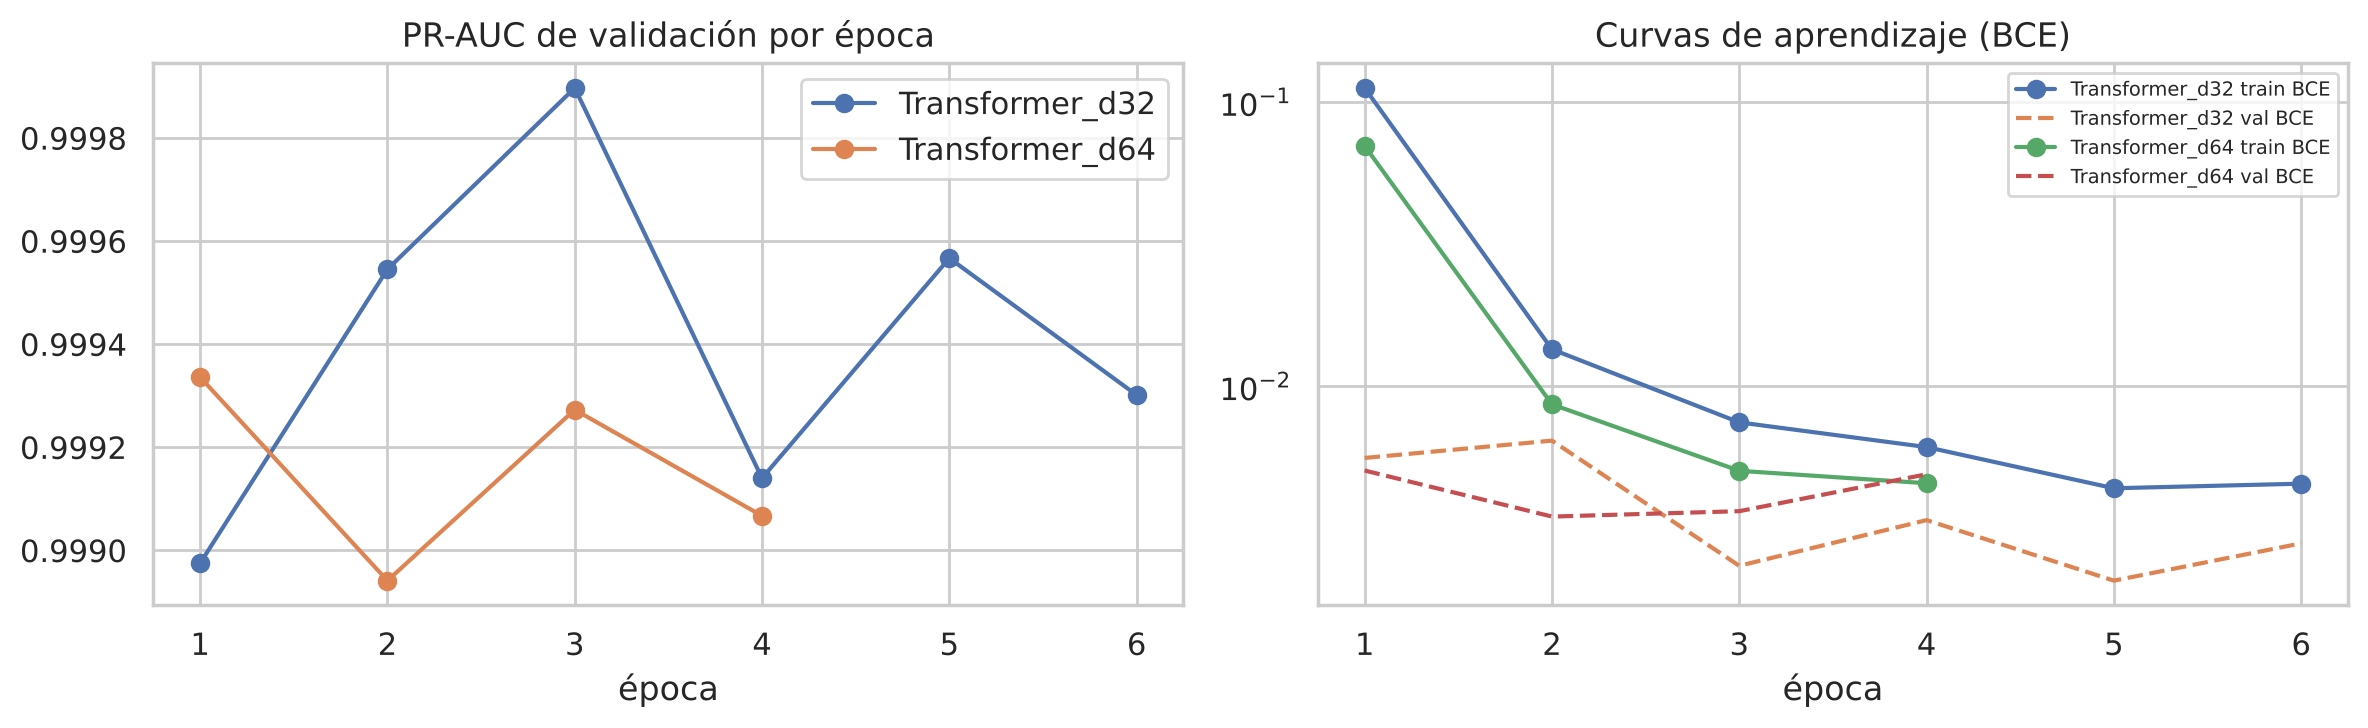

In [3]:
runs = {r[0]: r for r in week3_runs(ck)}
results, preds, hists, minutes = [], {}, {}, {}

def add_result(name, pb, pm, family, **extra):
    r, lead = evaluate(name, VA.yb, VA.ym, pb, pm, val_meta, failures)
    results.append({**r, 'family': family, **extra})
    preds[name] = (pb, pm)
    return r

for name, (pb, pm) in baseline.items():
    add_result(name, pb, pm, 'línea base')
add_result('TCN (semana 2)', pb_tcn, pm_tcn, 'semana 2', params=sum(p.numel() for p in tcn_w2.parameters()))

transformers = {}
for name in ['Transformer_d32', 'Transformer_d64']:
    _, arch, kw, seed = runs[name]
    model, hist, mins = fit_or_load(name, arch, L, TR, VA, 'oversample', seed, kw, MODEL_DIR, val_idx=val_es_idx)
    transformers[name] = model; hists[name] = hist; minutes[name] = mins
    pb, pm = predict(model, VA, L)
    add_result(name, pb, pm, 'semana 3', params=sum(p.numel() for p in model.parameters()), epochs=len(hist), train_min=mins)

res = pd.DataFrame(results).set_index('model')
cols = ['PR-AUC', 'ROC-AUC', 'recall', 'FP', 'F1_macro_comp', 'F1_macro_comp_direct', 'events_alerted_%', 'lead_median_h', 'Brier', 'ECE', 'params']
display(res[[c for c in cols if c in res]].round(4))

BEST_TF = res.loc[['Transformer_d32', 'Transformer_d64'], 'PR-AUC'].idxmax()
tf_model = transformers[BEST_TF]
print('Transformer kept (highest validation PR-AUC):', BEST_TF)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in hists.items():
    ax[0].plot(h['epoch'], h['val_pr_auc'], marker='o', label=name)
    ax[1].plot(h['epoch'], h['train_bce'], marker='o', label=f'{name} train BCE')
    ax[1].plot(h['epoch'], h['val_bce'], ls='--', label=f'{name} val BCE')
ax[0].set_title('PR-AUC de validación por época'); ax[0].set_xlabel('época'); ax[0].legend()
ax[1].set_title('Curvas de aprendizaje (BCE)'); ax[1].set_xlabel('época'); ax[1].set_yscale('log'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'transformer_learning_curves.png'), dpi=160); plt.show()

## 3.2 Incertidumbre y calibración

**MC Dropout vs. ensamble.** El modelo de la semana 2 quedó con dropout 0.023 (elegido por Optuna), así que muestrear las máscaras de dropout casi no cambia la predicción: MC Dropout subestimaría la incertidumbre. Se usa un **ensamble de 5 TCN** con la misma configuración y semillas 42–46 (la semilla 42 es el modelo de la semana 2). MC Dropout (30 pasadas) se reporta solo como comparación, también para el Transformer (dropout 0.1).

In [4]:
# MC Dropout (comparison)
mc = {}
for name, model in [('TCN (semana 2)', tcn_w2), (BEST_TF, tf_model)]:
    t0 = time.time()
    samples, _ = mc_dropout_predict(model, VA, L, T=30, seed=SEED)
    mc[name] = samples
    print(f'{name}: MC Dropout 30 passes in {time.time() - t0:.0f}s | mean std of p over all hours {samples.std(0).mean():.5f}, '
          f'on positive hours {samples.std(0)[VA.yb == 1].mean():.4f}')

# Ensemble of 5 TCN
members = [tcn_w2]
for s in ENSEMBLE_SEEDS[1:]:
    name, arch, kw, seed = runs[f'TCN_seed{s}']
    model, hist, mins = fit_or_load(name, arch, L, TR, VA, 'oversample', seed, kw, MODEL_DIR, val_idx=val_es_idx)
    members.append(model); hists[name] = hist; minutes[name] = mins
pbs_ens, pm_ens = ensemble_predict(members, VA, L)
pb_ens = pbs_ens.mean(0)
for k, s in enumerate(ENSEMBLE_SEEDS):
    print(f'member seed {s}: validation PR-AUC {average_precision_score(VA.yb, pbs_ens[k]):.4f}')
add_result('Ensamble 5 TCN', pb_ens, pm_ens, 'semana 3')
print('ensemble: mean std of p across members, all hours %.5f, positive hours %.4f' % (pbs_ens.std(0).mean(), pbs_ens.std(0)[VA.yb == 1].mean()))

TCN (semana 2): MC Dropout 30 passes in 320s | mean std of p over all hours 0.00033, on positive hours 0.0099


Transformer_d32: MC Dropout 30 passes in 110s | mean std of p over all hours 0.00022, on positive hours 0.0003


member seed 42: validation PR-AUC 0.9989
member seed 43: validation PR-AUC 0.9986
member seed 44: validation PR-AUC 0.9967
member seed 45: validation PR-AUC 0.9978
member seed 46: validation PR-AUC 0.9979
ensemble: mean std of p across members, all hours 0.00077, positive hours 0.0076


### Selección del modelo final (en validación)

Regla fijada antes de ver los números: gana el **menor costo esperado en validación** de la política de alertas de la sección 3.4 (cada modelo con su propio umbral óptimo de validación). Si dos modelos quedan a menos de 1 % de costo, gana el más simple (TCN individual < Transformer < ensamble). PR-AUC se reporta pero ya está saturada (≈ 0.999) y no discrimina.

In [5]:
sim_val = PolicySimulator(val_meta, failures)

def plateau_threshold(sweep):
    # Midpoint (median) of the thresholds that reach the minimum cost: robust to the exact edge of the plateau.
    best = sweep[sweep['cost'] == sweep['cost'].min()]
    return float(np.median(best['threshold'])), best

candidates = {'TCN (semana 2)': pb_tcn, BEST_TF: preds[BEST_TF][0], 'Ensamble 5 TCN': pb_ens}
sel_rows, sweeps = [], {}
for name, pb in candidates.items():
    sw = sim_val.sweep(pb, threshold_grid(pb)); sweeps[name] = sw
    thr, plateau = plateau_threshold(sw)
    r = sim_val.run(pb, thr)
    sel_rows.append({'model': name, 'threshold': thr, 'plateau': f'[{plateau.threshold.min():.3f}, {plateau.threshold.max():.3f}]',
                     'cost_val': r['cost'], 'failures_avoided': r['failures_avoided'], 'failures': r['failures'],
                     'false_alarms': r['false_alarms'], 'lead_mean_h': r['lead_mean_h'],
                     'PR-AUC': average_precision_score(VA.yb, pb)})
selection = pd.DataFrame(sel_rows).set_index('model')
display(selection.round(4))

simplicity = ['TCN (semana 2)', BEST_TF, 'Ensamble 5 TCN']
best_cost = selection['cost_val'].min()
tied = [m for m in simplicity if selection.loc[m, 'cost_val'] <= 1.01 * best_cost]
FINAL = tied[0]
print('final model:', FINAL, '| models within 1% of the best validation cost:', tied)
pb_final_raw = candidates[FINAL]
pm_final = {'TCN (semana 2)': pm_tcn, BEST_TF: preds[BEST_TF][1], 'Ensamble 5 TCN': pm_ens}[FINAL]

,threshold,plateau,cost_val,failures_avoided,failures,false_alarms,lead_mean_h,PR-AUC
model,,,,,,,,
TCN (semana 2),0.4800,"[0.430, 0.530]",355800,118,118,3,21.4322,0.9989
Transformer_d32,0.9981,"[0.997, 0.999]",354000,118,118,0,21.5169,0.9999
Ensamble 5 TCN,0.5500,"[0.540, 0.560]",356400,118,118,4,21.4068,0.9988


final model: TCN (semana 2) | models within 1% of the best validation cost: ['TCN (semana 2)', 'Transformer_d32', 'Ensamble 5 TCN']


### Calibración: diagrama de confiabilidad, Brier y *temperature scaling*

El sobremuestreo cambia la prevalencia que ve la red (≈ 50 % en entrenamiento contra 1.8 % real), así que sus probabilidades pueden quedar desplazadas. Se ajusta una temperatura escalar `T` sobre el logit binario minimizando la log-verosimilitud en validación (Guo et al., 2017). `T` no cambia el orden de las probabilidades, por lo que PR-AUC y el conjunto de alertas no cambian; solo cambia el significado del número que ve el operador. Como `T` se ajusta en validación, la verificación honesta de la calibración es la de prueba (sección final).

temperature T = 1.154 (softens the probabilities)
prevalencia real en validación = 0.0184


,Brier,ECE (15 bins por cuantil),NLL,p media
model,,,,
TCN (semana 2),0.00028,0.00007,0.00125,0.01849
Transformer_d32,0.00056,0.00092,0.00237,0.01934
Ensamble 5 TCN,0.00037,0.00054,0.00167,0.01896
TCN (semana 2) + temperatura,0.00028,0.00010,0.00122,0.01852


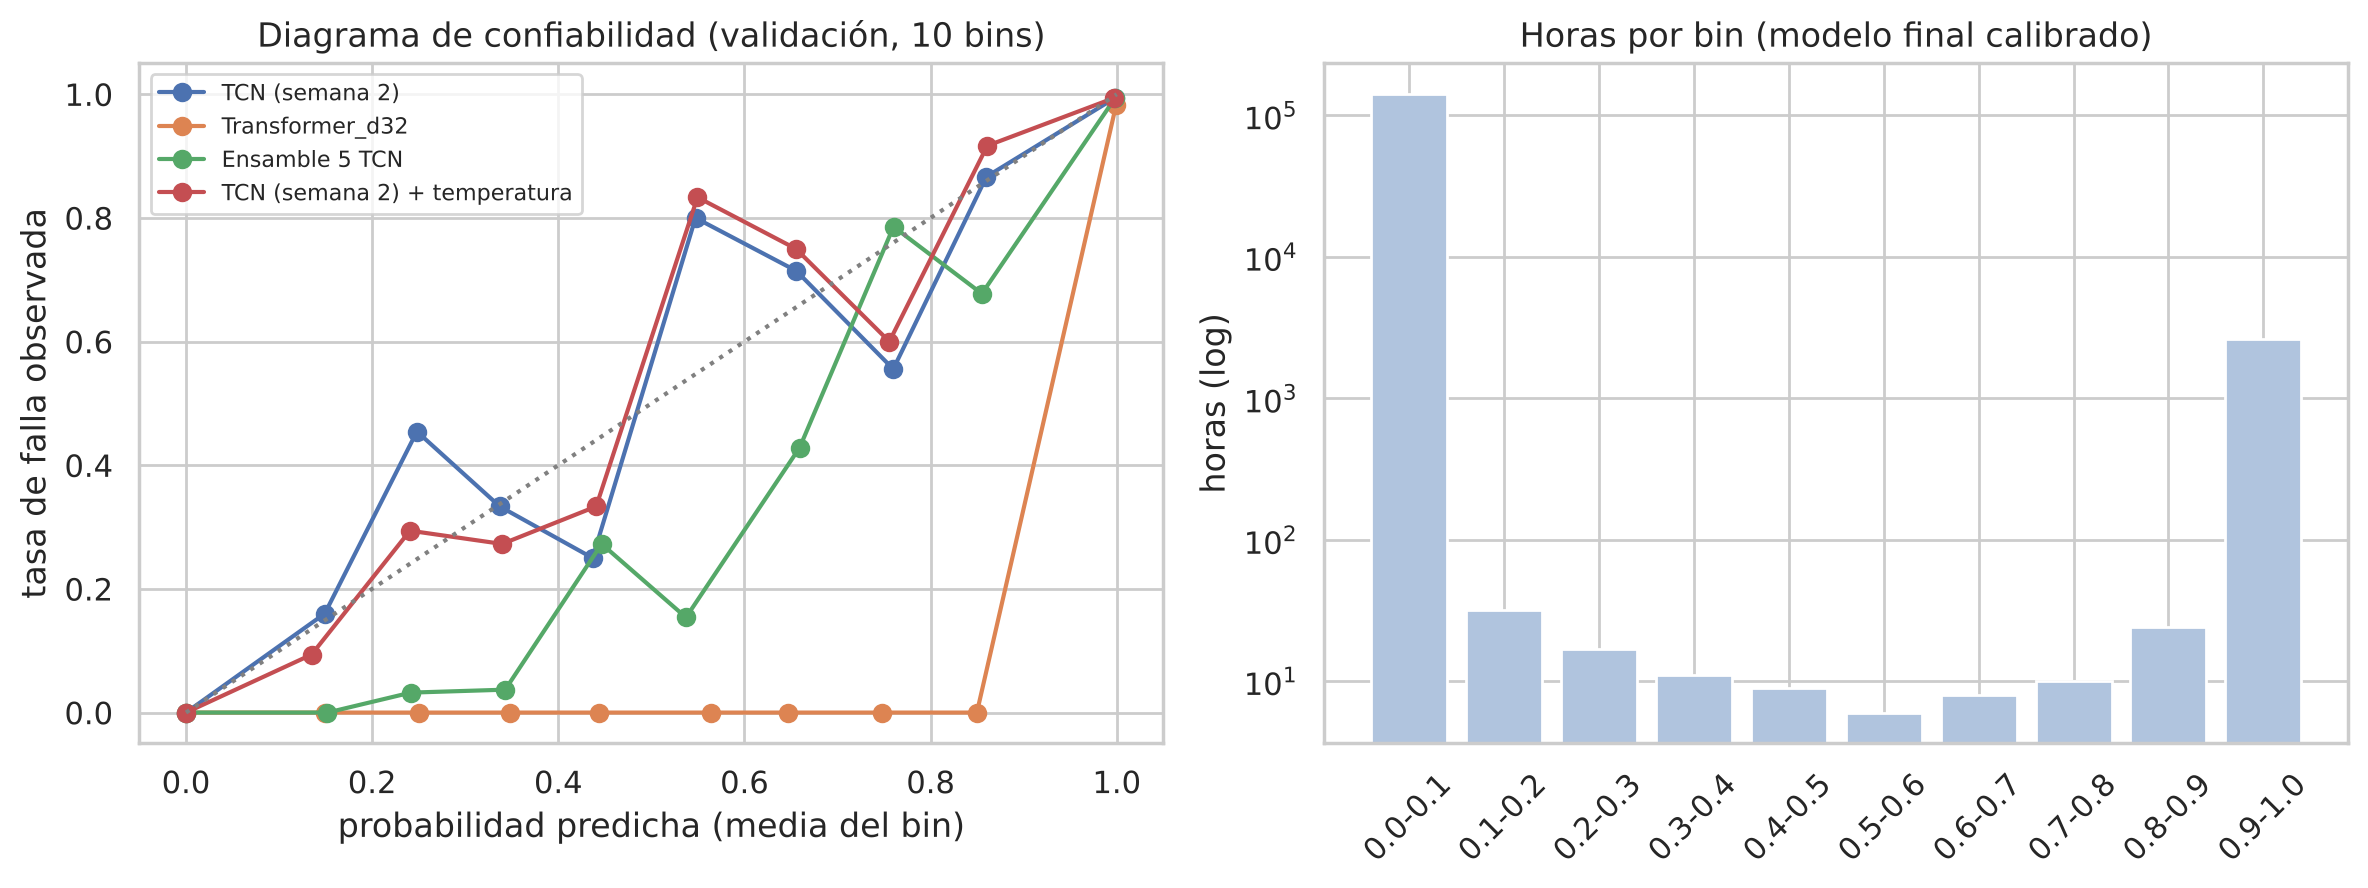

,grupo,horas,std media entre miembros
0,alerta correcta (y=1),2638,0.0064
1,falsa alarma (y=0),42,0.1584
2,"sin alerta, y=1",14,0.2208
3,"sin alerta, y=0",141306,0.0006


In [6]:
T_SCALE = fit_temperature(pb_final_raw, VA.yb)
pb_final = apply_temperature(pb_final_raw, T_SCALE)
print(f'temperature T = {T_SCALE:.3f} ({"softens" if T_SCALE > 1 else "sharpens"} the probabilities)')

cal_rows, curves = [], {}
for name, p in [('TCN (semana 2)', pb_tcn), (BEST_TF, preds[BEST_TF][0]), ('Ensamble 5 TCN', pb_ens), (f'{FINAL} + temperatura', pb_final)]:
    cal_rows.append({'model': name, 'Brier': brier_score_loss(VA.yb, p), 'ECE (15 bins por cuantil)': expected_calibration_error(VA.yb, p),
                     'NLL': -np.mean(VA.yb * np.log(np.clip(p, 1e-7, 1)) + (1 - VA.yb) * np.log(np.clip(1 - p, 1e-7, 1))),
                     'p media': p.mean()})
    curves[name] = reliability_table(VA.yb, p, bins=10)
calibration = pd.DataFrame(cal_rows).set_index('model')
print(f'prevalencia real en validación = {VA.yb.mean():.4f}')
display(calibration.round(5))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for name, c in curves.items():
    ax[0].plot(c['mean_p'], c['observed'], marker='o', label=name)
ax[0].plot([0, 1], [0, 1], ls=':', color='grey'); ax[0].set_xlabel('probabilidad predicha (media del bin)'); ax[0].set_ylabel('tasa de falla observada')
ax[0].set_title('Diagrama de confiabilidad (validación, 10 bins)'); ax[0].legend(fontsize=8)
c = curves[f'{FINAL} + temperatura']
ax[1].bar(range(len(c)), c['n'], color='lightsteelblue'); ax[1].set_yscale('log')
ax[1].set_xticks(range(len(c))); ax[1].set_xticklabels([f'{a:.1f}-{b:.1f}' for a, b in zip(c.lo, c.hi)], rotation=45)
ax[1].set_title('Horas por bin (modelo final calibrado)'); ax[1].set_ylabel('horas (log)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'reliability_validation.png'), dpi=160); plt.show()

# Uncertainty where it matters: disagreement between ensemble members on alert hours
thr_tmp = plateau_threshold(sweeps['Ensamble 5 TCN'])[0]
std = pbs_ens.std(0)
alert = pb_ens >= thr_tmp
unc = pd.DataFrame({'grupo': ['alerta correcta (y=1)', 'falsa alarma (y=0)', 'sin alerta, y=1', 'sin alerta, y=0'],
                    'horas': [int((alert & (VA.yb == 1)).sum()), int((alert & (VA.yb == 0)).sum()), int((~alert & (VA.yb == 1)).sum()), int((~alert & (VA.yb == 0)).sum())],
                    'std media entre miembros': [std[alert & (VA.yb == 1)].mean(), std[alert & (VA.yb == 0)].mean(), std[~alert & (VA.yb == 1)].mean(), std[~alert & (VA.yb == 0)].mean()]})
display(unc.round(4))

## 3.3 Interpretabilidad: gradientes integrados

*Integrated gradients* (Sundararajan et al., 2017) sobre la ventana dinámica `(24 h × 13 canales)`, con línea base = 0, que tras la normalización es la media de entrenamiento de cada canal (una hora "típica" sin errores y con edad media de los componentes), 50 pasos. Para cada componente `k` se atribuye el **logit de la clase k** de la cabeza multiclase en ventanas de validación que preceden a una falla real de `k` (hasta 200 por componente). Se usa el modelo final; si es un ensamble, se promedian las atribuciones de sus miembros. Se reporta la atribución firmada (dirección) y la absoluta (magnitud), por canal y por hora de la ventana.

IG done in 3s
Share of |attribution| per channel (columns sum to 1):


,comp1,comp2,comp3,comp4
volt,0.348,0.066,0.089,0.084
rotate,0.045,0.098,0.040,0.046
pressure,0.045,0.052,0.370,0.053
vibration,0.069,0.060,0.059,0.350
err1,0.355,0.002,0.003,0.003
err2,0.003,0.332,0.006,0.004
err3,0.005,0.310,0.004,0.006
err4,0.004,0.007,0.324,0.002
err5,0.010,0.001,0.006,0.358
h_comp1,0.044,0.016,0.019,0.019


Mean signed attribution per channel (positive = pushes toward that component):


,comp1,comp2,comp3,comp4
volt,5.754,-0.670,-0.540,-0.756
rotate,-0.367,3.040,-0.519,-0.605
pressure,-0.134,-0.960,7.845,-0.491
vibration,-0.797,-0.693,-0.716,7.279
err1,6.602,-0.000,0.067,-0.032
err2,-0.049,11.479,-0.072,-0.080
err3,-0.094,10.439,-0.094,-0.127
err4,-0.052,0.042,6.707,-0.035
err5,0.144,-0.032,0.069,7.818
h_comp1,0.807,-0.371,-0.246,-0.175


Top-3 channels per component: {'comp1': 'err1, volt, vibration', 'comp2': 'err2, err3, rotate', 'comp3': 'pressure, err4, volt', 'comp4': 'err5, vibration, volt'}


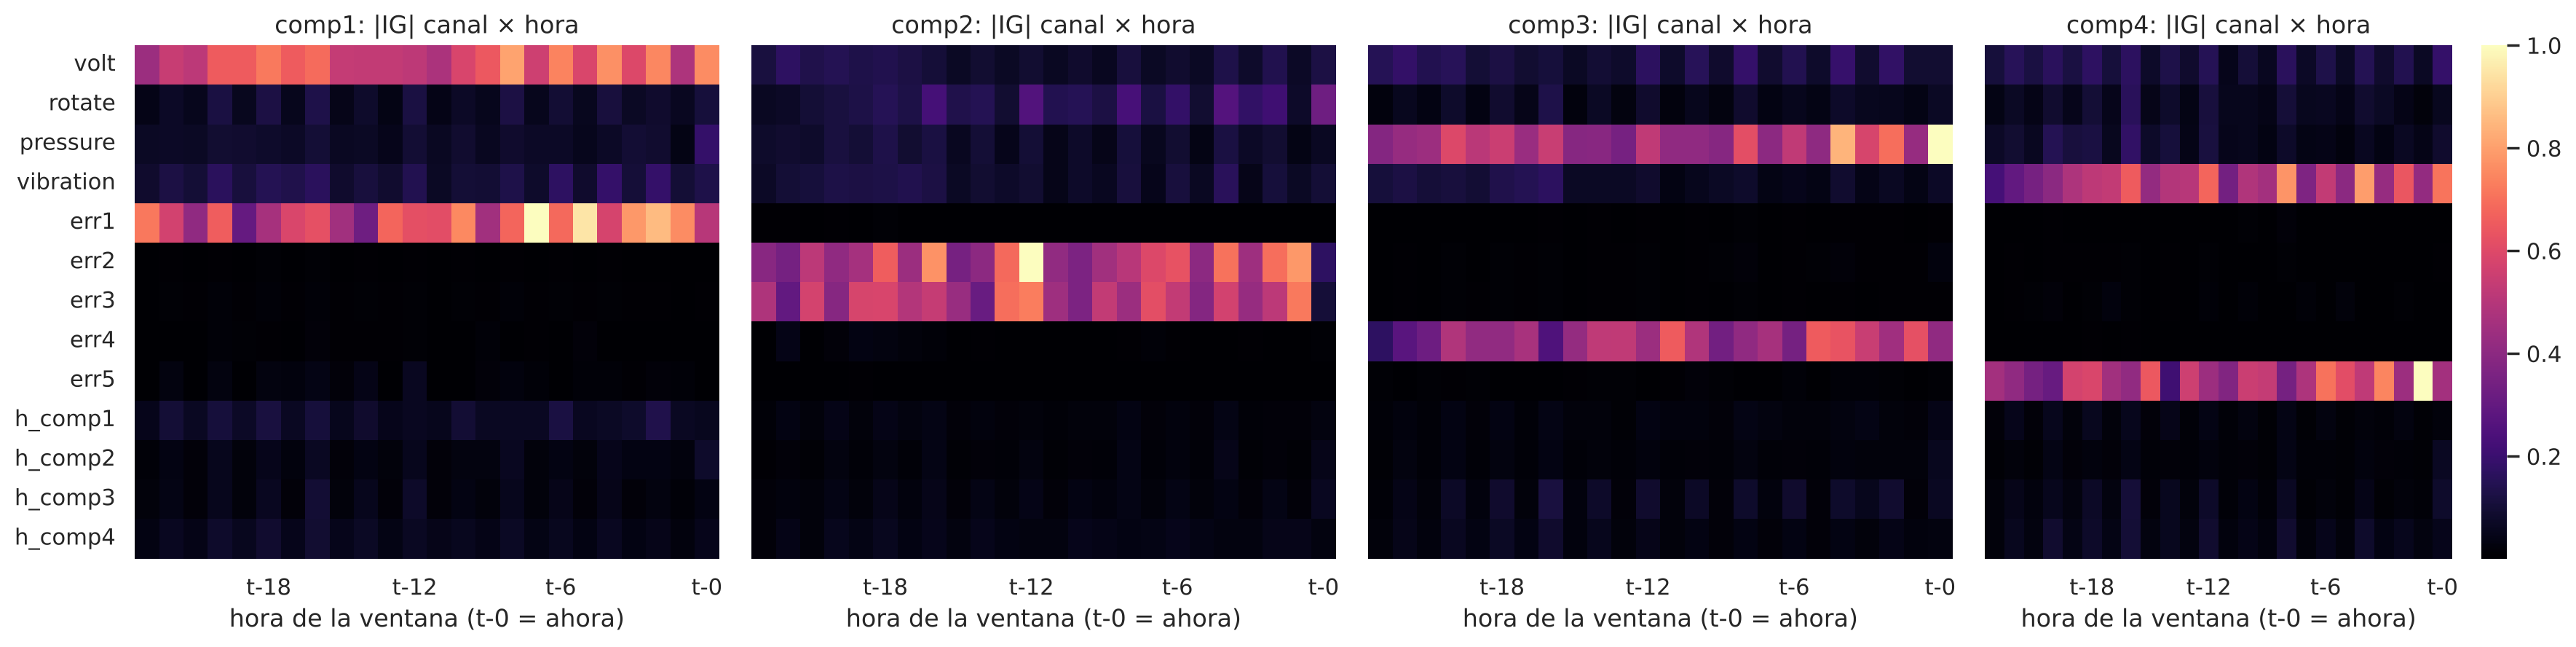

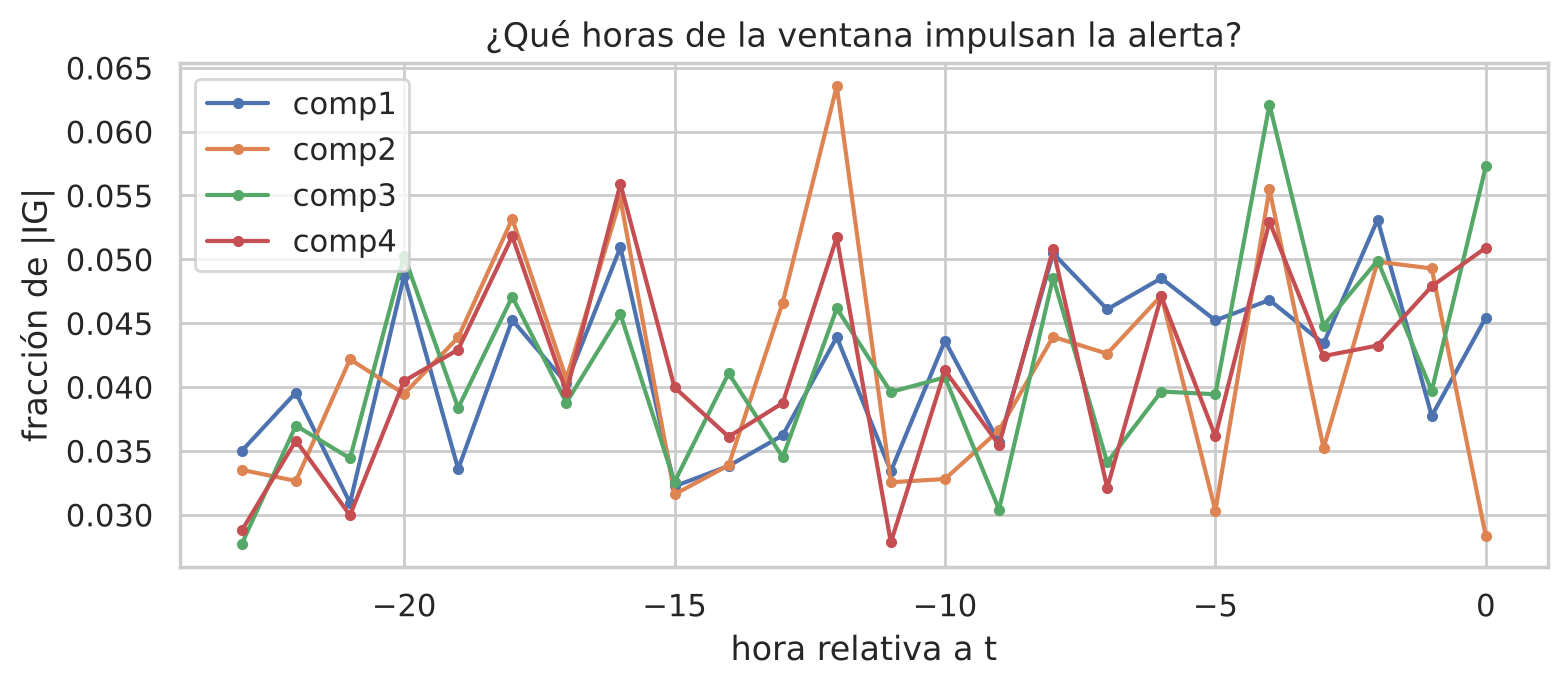

,comp1,comp2,comp3,comp4
sensores,0.507,0.276,0.558,0.532
errores,0.377,0.652,0.344,0.372
horas desde reemplazo,0.116,0.072,0.098,0.096


In [7]:
ig_models = members if FINAL == 'Ensamble 5 TCN' else [{'TCN (semana 2)': tcn_w2, BEST_TF: tf_model}[FINAL]]
rng = np.random.default_rng(SEED)
IG = {}
t0 = time.time()
for k, comp in enumerate(COMPS, start=1):
    idx = np.flatnonzero(VA.ym == k)
    idx = np.sort(rng.choice(idx, min(200, len(idx)), replace=False))
    x, m, a, _, _ = VA.batch(idx, L)
    att = torch.stack([integrated_gradients(mod, x, m, a, target=k, steps=50) for mod in ig_models]).mean(0).numpy()
    IG[comp] = att
print(f'IG done in {time.time() - t0:.0f}s')

short = ['volt', 'rotate', 'pressure', 'vibration', 'err1', 'err2', 'err3', 'err4', 'err5', 'h_comp1', 'h_comp2', 'h_comp3', 'h_comp4']
by_channel = pd.DataFrame({c: np.abs(IG[c]).sum(1).mean(0) for c in COMPS}, index=short)
share = by_channel / by_channel.sum(0)
signed = pd.DataFrame({c: IG[c].sum(1).mean(0) for c in COMPS}, index=short)
print('Share of |attribution| per channel (columns sum to 1):'); display(share.round(3))
print('Mean signed attribution per channel (positive = pushes toward that component):'); display(signed.round(3))
top3 = {c: ', '.join(share[c].sort_values(ascending=False).index[:3]) for c in COMPS}
print('Top-3 channels per component:', top3)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharey=True)
for ax, comp in zip(axes, COMPS):
    hm = np.abs(IG[comp]).mean(0).T                   # (channels, hours)
    sns.heatmap(hm / hm.max(), ax=ax, cmap='magma', cbar=comp == COMPS[-1], yticklabels=short,
                xticklabels=[f't-{L - 1 - j}' if (L - 1 - j) % 6 == 0 else '' for j in range(L)])
    ax.set_title(f'{comp}: |IG| canal × hora'); ax.set_xlabel('hora de la ventana (t-0 = ahora)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'ig_heatmaps.png'), dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
for comp in COMPS:
    prof = np.abs(IG[comp]).sum(2).mean(0)
    ax.plot(range(-(L - 1), 1), prof / prof.sum(), marker='.', label=comp)
ax.set_xlabel('hora relativa a t'); ax.set_ylabel('fracción de |IG|'); ax.set_title('¿Qué horas de la ventana impulsan la alerta?'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'ig_time_profile.png'), dpi=160); plt.show()

# Signal per hour inside the window for the two dominant non-maintenance channel groups
sens_err = pd.DataFrame({c: [np.abs(IG[c][:, :, :4]).sum() / np.abs(IG[c]).sum(), np.abs(IG[c][:, :, 4:9]).sum() / np.abs(IG[c]).sum(),
                             np.abs(IG[c][:, :, 9:]).sum() / np.abs(IG[c]).sum()] for c in COMPS},
                        index=['sensores', 'errores', 'horas desde reemplazo'])
display(sens_err.round(3))

### Contraste con el análisis exploratorio de la semana 1

* **Coincide.** En la semana 1, los errores eran entre 11 y 35 veces más frecuentes en las 24 h previas a una falla que en periodos sanos, y los cuatro sensores se desviaban en las 0–48 h previas (volt 170.6 → 175.9, rotate 447.7 → 418.4, pressure 100.7 → 105.4, vibration 40.3 → 42.8), mientras que entre 48 y 72 h eran indistinguibles de lo sano. Los gradientes integrados reparten la atribución en toda la ventana de 24 h, sin pico en las últimas horas: la evidencia útil está en el último día, coherente con que alargar L no ayudó en la semana 2.
* **Lo precisa.** El EDA mostraba desviaciones agregadas; el modelo muestra que cada componente tiene su propio par sensor–error, que concentra entre 69 y 74 % de la atribución: comp1 ↔ volt + error1, comp2 ↔ error2 + error3 + rotate, comp3 ↔ pressure + error4, comp4 ↔ vibration + error5. La atribución con signo es positiva para su componente y negativa o casi nula para los demás.
* **Difiere de la línea base.** En XGBoost, las horas desde el reemplazo eran el grupo dominante (sin ellas, PR-AUC 0.34–0.40). En la TCN reciben solo entre 7 y 12 % de la atribución: la red extrae la forma temporal de sensores y errores, que el modelo de rezagos no aprovechaba, y depende menos del sustituto "edad del componente".

## 3.4 Política de mantenimiento

**Simulación por evento** (la misma para validación y prueba):

* **Alerta**: a la hora `t` cuando la probabilidad del modelo lleva al menos 3 horas seguidas sobre el umbral (misma definición de alerta sostenida que el tiempo de anticipación de la semana 2). La decisión se toma en `t`, cuando ya existe la evidencia. Una alerta dispara una intervención; no se emite otra alerta en la misma máquina durante las 24 h siguientes.
* **Intervención acertada** (3 000): alguna falla real de componente ocurre en `(t, t + 24 h]`; se cobra por componente cubierto y la falla se considera evitada.
* **Falsa alarma** (600): no ocurre ninguna falla en esas 24 h.
* **Falla no anticipada** (15 000): falla de componente sin alerta en las 24 h previas.

**Referencias.**
1. *Operar hasta la falla*: todas las fallas cuestan 15 000.
2. *Reemplazo por calendario de cada componente*: cada componente se reemplaza (3 000, intervención planeada) cuando su edad llega a `T_k` horas, sobre la línea de tiempo real de cada máquina. Los reemplazos programados que la planta ya hace siguen ocurriendo en todas las políticas. Una falla real cuenta como evitada si hubo un reemplazo planeado después del último reemplazo real del componente. `T_k` se elige minimizando el costo en enero–octubre (entrenamiento + validación; el calendario no tiene parámetros entrenados, así que usar ambos periodos da más fallas para elegir `T_k` sin tocar prueba).

**Umbral.** Se barre el umbral sobre las probabilidades calibradas del modelo final en validación y se toma la mediana de la meseta de costo mínimo.

threshold = 0.4800 (plateau of minimum cost: 0.4400 - 0.5200, 9 grid points)
{'threshold': 0.48000000000000004, 'alerts': 115, 'false_alarms': 3, 'failures': 118, 'failures_avoided': 118, 'failures_missed': 0, 'cost': 355800, 'lead_mean_h': np.float64(21.43220338983051), 'days': 60.0}


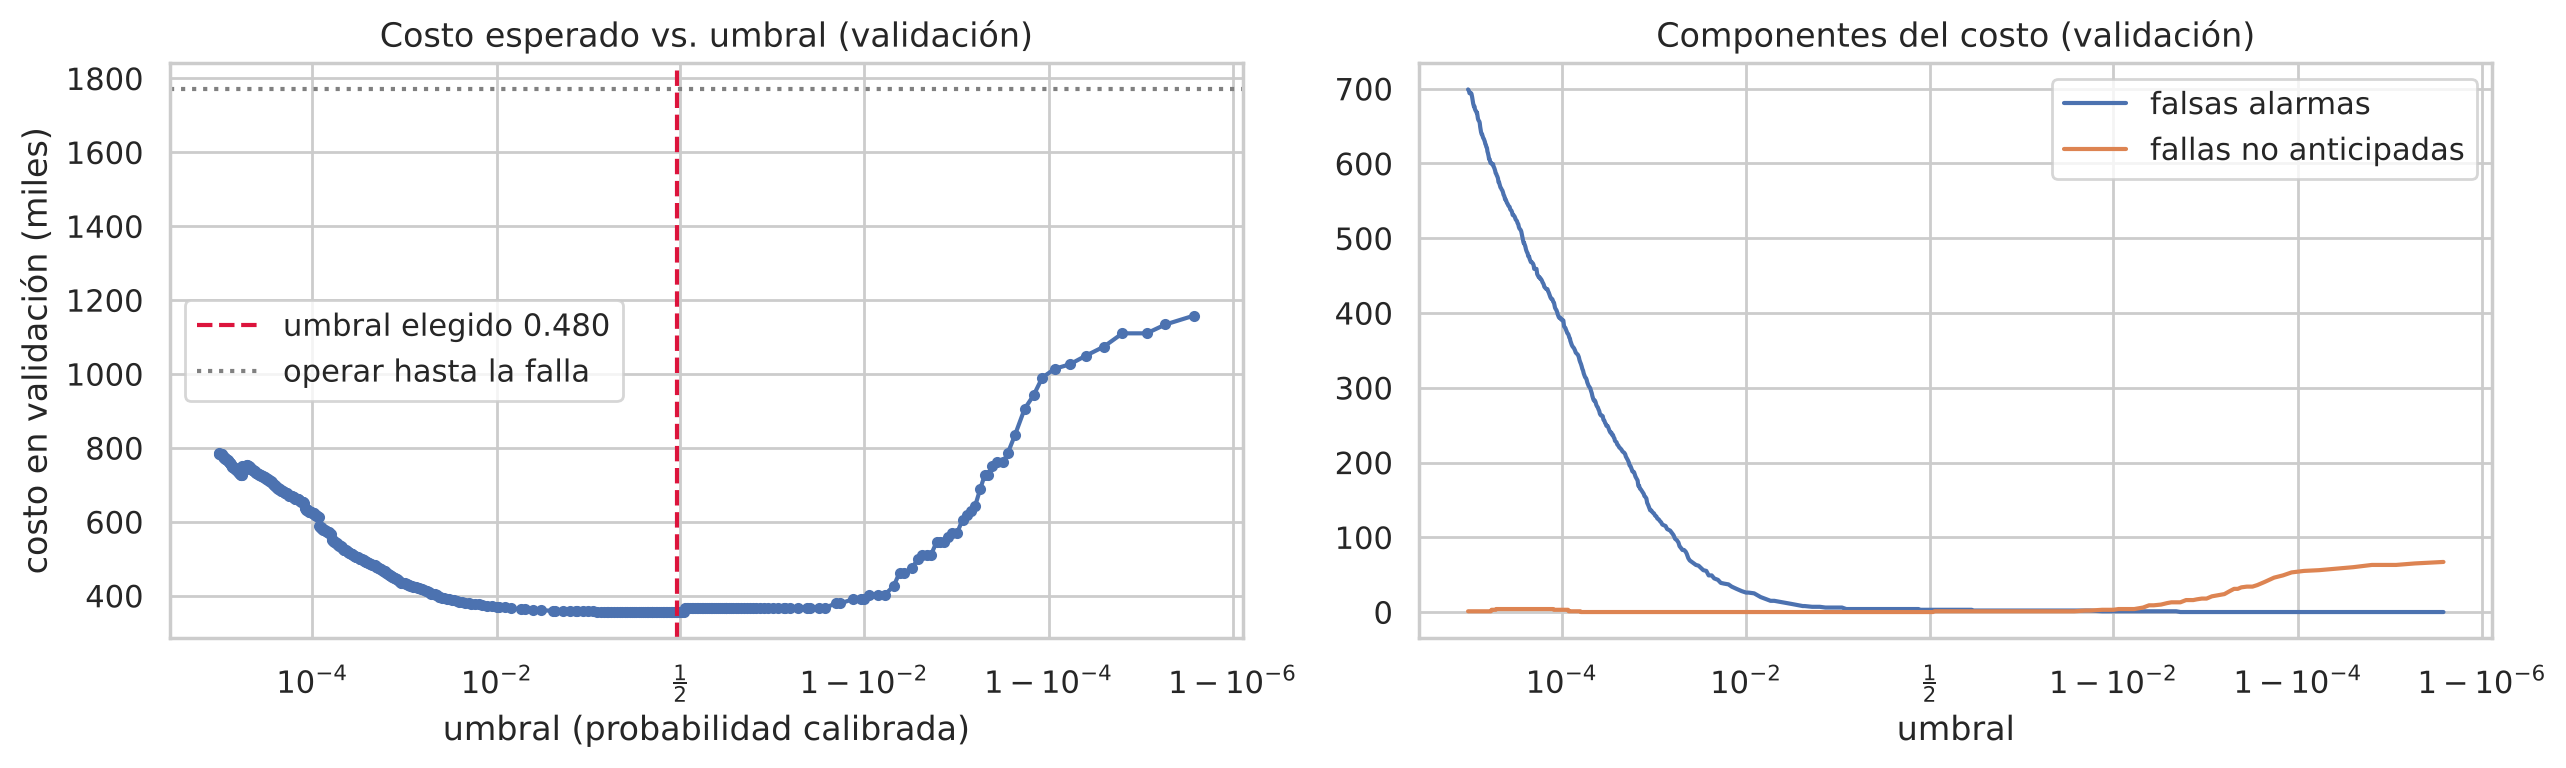

comp1: T* = 1056 h (44 days) | Jan-Oct: 509 planned, 152/162 failures avoided


comp2: T* = 1416 h (59 days) | Jan-Oct: 283 planned, 120/214 failures avoided


comp3: T* = 2328 h (97 days) | Jan-Oct: 107 planned, 55/111 failures avoided


comp4: T* = 1656 h (69 days) | Jan-Oct: 225 planned, 111/153 failures avoided


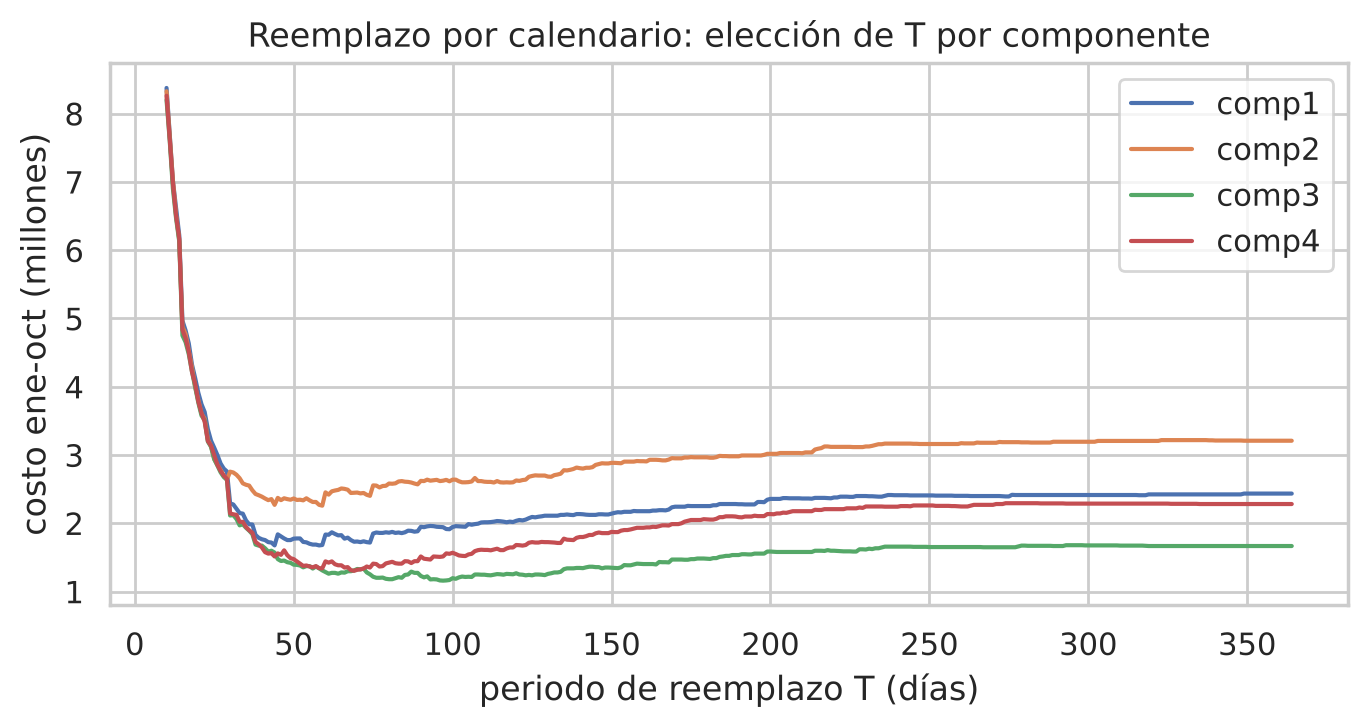

,comp,T_h,planned_replacements,failures,failures_avoided,failures_missed,cost
0,comp1,1056,98,21,21,0,294000
1,comp2,1416,56,46,24,22,498000
2,comp3,2328,13,20,5,15,264000
3,comp4,1656,47,31,21,10,291000


decisions frozen in data/processed/week3_decisions.json
{
 "final_model": "TCN (semana 2)",
 "transformer_kept": "Transformer_d32",
 "temperature": 1.1542251366756358,
 "threshold": 0.48000000000000004,
 "sustain_h": 3,
 "cooldown_h": 24,
 "calendar_T_h": {
  "comp1": 1056,
  "comp2": 1416,
  "comp3": 2328,
  "comp4": 1656
 },
 "costs": {
  "failure": 15000,
  "hit": 3000,
  "false_alarm": 600
 },
 "ensemble_seeds": [
  42,
  43,
  44,
  45,
  46
 ],
 "decided_on": "train + validation only",
 "written_at": "2026-11-26T17:40:35.399033"
}


In [8]:
sw_final = sim_val.sweep(pb_final, threshold_grid(pb_final))
THRESHOLD, plateau = plateau_threshold(sw_final)
val_policy = sim_val.run(pb_final, THRESHOLD)
print(f'threshold = {THRESHOLD:.4f} (plateau of minimum cost: {plateau.threshold.min():.4f} - {plateau.threshold.max():.4f}, {len(plateau)} grid points)')
print({k: v for k, v in val_policy.items() if not k.startswith('_')})

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
s = sw_final.sort_values('threshold')
ax[0].plot(s['threshold'], s['cost'] / 1e3, marker='.')
ax[0].axvline(THRESHOLD, color='crimson', ls='--', label=f'umbral elegido {THRESHOLD:.3f}')
ax[0].axhline(run_to_failure_cost(val_policy['failures']) / 1e3, color='grey', ls=':', label='operar hasta la falla')
ax[0].set_xscale('logit'); ax[0].set_xlabel('umbral (probabilidad calibrada)'); ax[0].set_ylabel('costo en validación (miles)'); ax[0].legend()
ax[0].set_title('Costo esperado vs. umbral (validación)')
ax[1].plot(s['threshold'], s['false_alarms'], label='falsas alarmas'); ax[1].plot(s['threshold'], s['failures_missed'], label='fallas no anticipadas')
ax[1].set_xscale('logit'); ax[1].set_xlabel('umbral'); ax[1].legend(); ax[1].set_title('Componentes del costo (validación)')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'cost_vs_threshold.png'), dpi=160); plt.show()

# Calendar periods chosen on Jan-Oct
CAL_START, CAL_END = pd.Timestamp('2015-01-01'), T_TEST
cal_T, cal_curves = {}, {}
for comp in COMPS:
    best, rows = best_calendar(maint, failures, comp, CAL_START, CAL_END)
    cal_T[comp] = int(best['T_h']); cal_curves[comp] = rows
    print(f'{comp}: T* = {cal_T[comp]} h ({cal_T[comp] / 24:.0f} days) | Jan-Oct: {int(best.planned_replacements)} planned, '
          f'{int(best.failures_avoided)}/{int(best.failures)} failures avoided')

fig, ax = plt.subplots(figsize=(7, 3.8))
for comp, rows in cal_curves.items():
    ax.plot(rows['T_h'] / 24, rows['cost'] / 1e6, label=comp)
ax.set_xlabel('periodo de reemplazo T (días)'); ax.set_ylabel('costo ene-oct (millones)'); ax.set_title('Reemplazo por calendario: elección de T por componente'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'calendar_T.png'), dpi=160); plt.show()

def calendar_policy(start, end, T=cal_T, costs=COSTS, per_machine=False):
    res = [simulate_calendar(maint, failures, c, T[c], start, end, costs) for c in COMPS]
    rows = pd.DataFrame([{k: v for k, v in r.items() if k != 'per_machine'} for r in res])
    if not per_machine:
        return rows
    pm = {}
    for r in res:
        for mid_, v in r['per_machine'].items():
            pm[mid_] = pm.get(mid_, 0) + v
    return rows, pm

vlo, vhi = sim_val.fail.datetime.min(), val_meta.datetime.max() + pd.Timedelta(hours=24)
cal_val = calendar_policy(val_meta.datetime.min(), vhi)
display(cal_val)

decisions = {'final_model': FINAL, 'transformer_kept': BEST_TF, 'temperature': T_SCALE, 'threshold': THRESHOLD,
             'sustain_h': 3, 'cooldown_h': 24, 'calendar_T_h': cal_T, 'costs': COSTS, 'ensemble_seeds': ENSEMBLE_SEEDS,
             'decided_on': 'train + validation only', 'written_at': pd.Timestamp.now().isoformat()}
with open(DECISIONS, 'w') as f:
    json.dump(decisions, f, indent=1)
print('decisions frozen in', DECISIONS); print(json.dumps(decisions, indent=1))

## Evaluación final en prueba (se ejecuta una sola vez)

Se leen las decisiones congeladas y se aplican tal cual al periodo 1 nov – 31 dic 2015. Nada de lo que sigue cambia el modelo, la temperatura, el umbral ni los periodos de calendario.

test rows 146400 positive rate 0.0183 | final model: TCN (semana 2)


,prueba
PR-AUC,0.9963
ROC-AUC,0.9999
recall @ precisión ≥ 0.80,1.0000
precisión (umbral de costo),0.9575
recall (umbral de costo),0.9903
F1 macro comp (umbral de costo),0.9688
F1 macro comp (argmax directo),0.9719
F1 comp1,0.9476
F1 comp2,1.0000
F1 comp3,0.9428


{'threshold': 0.48000000000000004, 'alerts': 126, 'false_alarms': 12, 'failures': 121, 'failures_avoided': 121, 'failures_missed': 0, 'cost': 370200, 'lead_mean_h': np.float64(21.016528925619834), 'days': 61.0}


,comp,T_h,planned_replacements,failures,failures_avoided,failures_missed,cost
0,comp1,1056,105,30,30,0,315000
1,comp2,1416,63,45,24,21,504000
2,comp3,2328,17,20,4,16,291000
3,comp4,1656,41,26,15,11,288000


alerts that hit a failure and name (one of) the failing component(s): 100.0% of 114


,sin temperatura,con temperatura
Brier,0.00077,0.00076
ECE,0.00064,0.00066


Reliability bins on test (calibrated model): hours per bin, mean predicted p and observed failure rate


,bin,lo,hi,n,mean_p,observed
0,0,0.0,0.1,143527,0.000,0.000
1,1,0.1,0.2,37,0.144,0.135
2,2,0.2,0.3,23,0.247,0.217
3,3,0.3,0.4,13,0.349,0.231
4,4,0.4,0.5,28,0.448,0.357
5,5,0.5,0.6,22,0.554,0.273
6,6,0.6,0.7,17,0.654,0.353
7,7,0.7,0.8,28,0.767,0.500
8,8,0.8,0.9,42,0.857,0.595
9,9,0.9,1.0,2663,0.996,0.978


hours with 0.1 <= p < 0.9: 210 of 146400 (0.14 %)


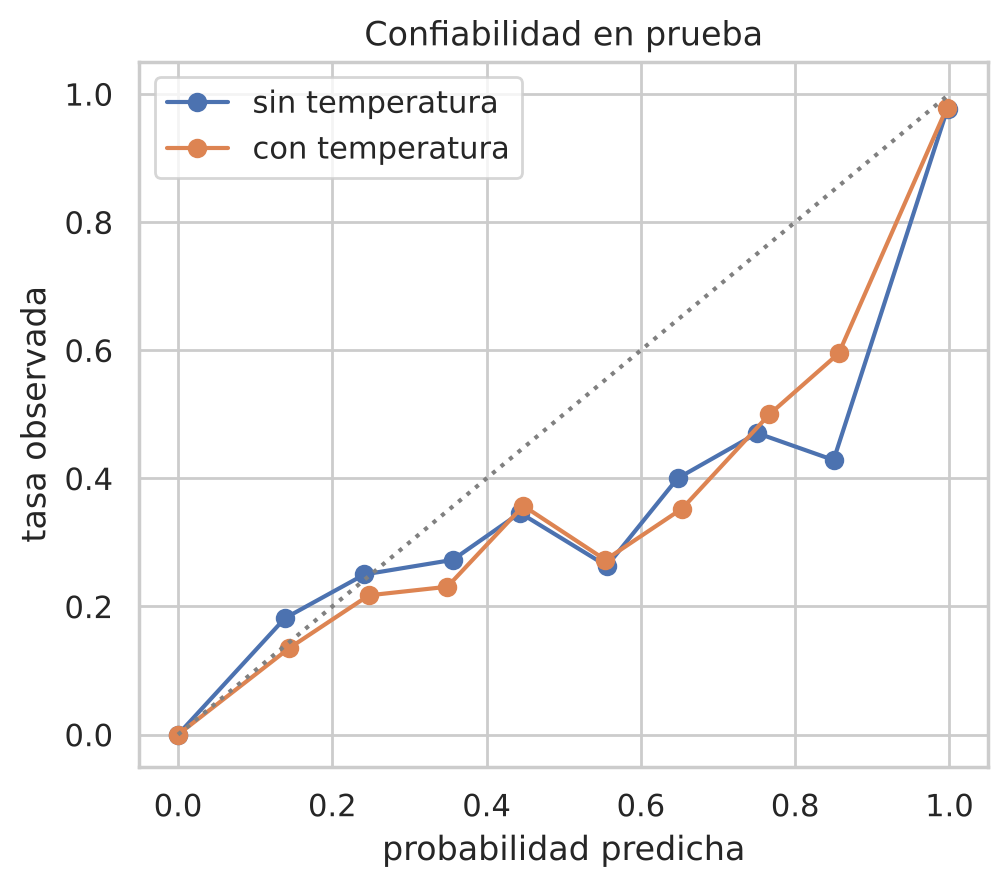

In [9]:
with open(DECISIONS) as f:
    D = json.load(f)
te_df = load_split('test', machines)
TE = SplitData(te_df, store, ck['age_stats'])
test_meta = TE.df[['machineID', 'datetime']]
model_list = {'TCN (semana 2)': [tcn_w2], D['transformer_kept']: [tf_model], 'Ensamble 5 TCN': members}[D['final_model']]
pbs_te, pm_te = ensemble_predict(model_list, TE, L)
pb_te = apply_temperature(pbs_te.mean(0), D['temperature'])
print('test rows', len(TE), 'positive rate %.4f' % TE.yb.mean(), '| final model:', D['final_model'])

# Threshold-free metrics and metrics at the frozen cost threshold
r_te, lead_te = evaluate(D['final_model'] + ' (prueba)', TE.yb, TE.ym, pb_te, pm_te, test_meta, failures, thr=D['threshold'])
rec80 = threshold_at_precision(TE.yb, pb_te)   # recall at precision >= 0.80 (threshold-free summary, NOT used for decisions)
pred80 = pb_te >= rec80
test_metrics = pd.Series({'PR-AUC': r_te['PR-AUC'], 'ROC-AUC': r_te['ROC-AUC'], 'recall @ precisión ≥ 0.80': pred80[TE.yb == 1].mean(),
                          'precisión (umbral de costo)': r_te['precision'], 'recall (umbral de costo)': r_te['recall'],
                          'F1 macro comp (umbral de costo)': r_te['F1_macro_comp'], 'F1 macro comp (argmax directo)': r_te['F1_macro_comp_direct'],
                          **{f'F1 {c}': r_te[f'F1_{c}'] for c in COMPS},
                          'eventos con alerta sostenida (%)': r_te['events_alerted_%'], 'anticipación mediana (h)': r_te['lead_median_h'],
                          'Brier': r_te['Brier'], 'ECE': r_te['ECE']})
display(test_metrics.round(4).to_frame('prueba'))

sim_te = PolicySimulator(test_meta, failures)
te_policy = sim_te.run(pb_te, D['threshold'])
cal_te, cal_te_pm = calendar_policy(test_meta.datetime.min(), test_meta.datetime.max() + pd.Timedelta(hours=24),
                                    T={k: v for k, v in D['calendar_T_h'].items()}, per_machine=True)
print({k: v for k, v in te_policy.items() if not k.startswith('_')})
display(cal_te)

# Does the alert point to the right component? (multiclass head at the alert hour)
pm_sorted_correct = []
for row, hit, fidx in te_policy['_alerts']:
    if hit:
        pred_comp = COMPS[int(pm_te[row, 1:].argmax())]
        pm_sorted_correct.append(pred_comp in set(sim_te.fail.loc[fidx, 'failure']))
comp_ok = float(np.mean(pm_sorted_correct))
print(f'alerts that hit a failure and name (one of) the failing component(s): {100 * comp_ok:.1f}% of {len(pm_sorted_correct)}')

# Calibration on test (honest check of the temperature)
cal_test = pd.DataFrame({'sin temperatura': [brier_score_loss(TE.yb, pbs_te.mean(0)), expected_calibration_error(TE.yb, pbs_te.mean(0))],
                         'con temperatura': [brier_score_loss(TE.yb, pb_te), expected_calibration_error(TE.yb, pb_te)]}, index=['Brier', 'ECE'])
display(cal_test.round(5))
rel_te = reliability_table(TE.yb, pb_te, bins=10)
print('Reliability bins on test (calibrated model): hours per bin, mean predicted p and observed failure rate')
display(rel_te.round(3))
mid_bins = rel_te[(rel_te.lo >= 0.1) & (rel_te.hi <= 0.9)]
print(f'hours with 0.1 <= p < 0.9: {int(mid_bins.n.sum())} of {len(TE)} ({100 * mid_bins.n.sum() / len(TE):.2f} %)')
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for name, p in [('sin temperatura', pbs_te.mean(0)), ('con temperatura', pb_te)]:
    c = reliability_table(TE.yb, p, bins=10); ax.plot(c['mean_p'], c['observed'], marker='o', label=name)
ax.plot([0, 1], [0, 1], ls=':', color='grey'); ax.set_xlabel('probabilidad predicha'); ax.set_ylabel('tasa observada')
ax.set_title('Confiabilidad en prueba'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'reliability_test.png'), dpi=160); plt.show()

### Costo anual estimado de las tres políticas

Costo de cada periodo anualizado con `× 365 / días del periodo` (validación: 60 días, prueba: 61 días). Flota de 100 máquinas. La fila de prueba es el resultado que se reporta; la de validación es donde se tomaron las decisiones.

In [10]:
def policy_table(sim, model_run, cal_rows, label):
    days = sim.n_hours / 24
    n_fail = len(sim.fail); weeks = days / 7
    rtf = run_to_failure_cost(n_fail)
    rows = [
        {'política': 'Operar hasta la falla', 'fallas evitadas': 0, 'fallas no anticipadas': n_fail, 'intervenciones planeadas': 0,
         'falsas alarmas': 0, 'costo periodo': rtf},
        {'política': 'Reemplazo por calendario', 'fallas evitadas': int(cal_rows.failures_avoided.sum()), 'fallas no anticipadas': int(cal_rows.failures_missed.sum()),
         'intervenciones planeadas': int(cal_rows.planned_replacements.sum()), 'falsas alarmas': np.nan, 'costo periodo': int(cal_rows.cost.sum())},
        {'política': 'Alertas del modelo', 'fallas evitadas': model_run['failures_avoided'], 'fallas no anticipadas': model_run['failures_missed'],
         'intervenciones planeadas': model_run['alerts'], 'falsas alarmas': model_run['false_alarms'], 'costo periodo': model_run['cost']},
    ]
    t = pd.DataFrame(rows).set_index('política')
    t['costo anual (M)'] = t['costo periodo'] * 365 / days / 1e6
    t['ahorro anual vs operar hasta la falla (M)'] = (rtf - t['costo periodo']) * 365 / days / 1e6
    t['falsas alarmas / semana'] = t['falsas alarmas'] / weeks
    t.insert(0, 'conjunto', label)
    return t

annual = pd.concat([policy_table(sim_val, val_policy, cal_val, f'validación ({sim_val.n_hours / 24:.0f} d)'),
                    policy_table(sim_te, te_policy, cal_te, f'prueba ({sim_te.n_hours / 24:.0f} d)')])
display(annual.round(3))
annual.to_csv(os.path.join(OUT_DIR, 'week3_annual_cost.csv'))

# 95 % bootstrap intervals on test: resample the 100 machines with replacement (same draw for every policy)
machine_of_row = test_meta['machineID'].to_numpy()
rtf_pm = (sim_te.fail.groupby('machineID').size() * COSTS['failure']).to_dict()
model_pm = model_cost_per_machine(sim_te, te_policy, machine_of_row)
boot = bootstrap_annual({'Operar hasta la falla': rtf_pm, 'Reemplazo por calendario': cal_te_pm, 'Alertas del modelo': model_pm},
                        sorted(machines.machineID), sim_te.n_hours / 24, n=2000, seed=SEED)
assert abs(sum(model_pm.values()) - te_policy['cost']) < 1e-6 and abs(sum(cal_te_pm.values()) - cal_te.cost.sum()) < 1e-6
ci = pd.DataFrame({k: {'costo anual (M)': np.mean(v), 'IC 95 % inf.': np.percentile(v, 2.5), 'IC 95 % sup.': np.percentile(v, 97.5)}
                   for k, v in boot.items()}).T
for name, a, b in [('ahorro modelo vs operar hasta la falla', 'Operar hasta la falla', 'Alertas del modelo'),
                   ('ahorro modelo vs calendario', 'Reemplazo por calendario', 'Alertas del modelo')]:
    d = boot[a] - boot[b]
    ci.loc[name] = [d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)]
print('Test, annualised, 95 % bootstrap interval over machines (2000 resamples):')
display(ci.round(2))
ci.to_csv(os.path.join(OUT_DIR, 'week3_annual_cost_bootstrap.csv'))
print(f'test: mean warning time of avoided failures = {te_policy["lead_mean_h"]:.1f} h; '
      f'{te_policy["false_alarms"] / (sim_te.n_hours / 24 / 7):.2f} false alarms per week for the 100-machine fleet')

,conjunto,fallas evitadas,fallas no anticipadas,intervenciones planeadas,falsas alarmas,costo periodo,costo anual (M),ahorro anual vs operar hasta la falla (M),falsas alarmas / semana
política,,,,,,,,,
Operar hasta la falla,validación (60 d),0,118,0,0.0,1770000,10.768,0.000,0.000
Reemplazo por calendario,validación (60 d),71,47,214,NaN,1347000,8.194,2.573,NaN
Alertas del modelo,validación (60 d),118,0,115,3.0,355800,2.164,8.603,0.350
Operar hasta la falla,prueba (61 d),0,121,0,0.0,1815000,10.860,0.000,0.000
Reemplazo por calendario,prueba (61 d),73,48,226,NaN,1398000,8.365,2.495,NaN
Alertas del modelo,prueba (61 d),121,0,126,12.0,370200,2.215,8.645,1.377


Test, annualised, 95 % bootstrap interval over machines (2000 resamples):


,costo anual (M),IC 95 % inf.,IC 95 % sup.
Operar hasta la falla,10.84,9.24,12.48
Reemplazo por calendario,8.36,7.22,9.57
Alertas del modelo,2.21,1.88,2.54
ahorro modelo vs operar hasta la falla,8.63,7.33,9.93
ahorro modelo vs calendario,6.15,5.19,7.15


test: mean warning time of avoided failures = 21.0 h; 1.38 false alarms per week for the 100-machine fleet


### Análisis de sensibilidad: razón costo de falla / costo de falsa alarma

Se fija la falsa alarma en 600 y la intervención acertada en 3 000, y se varía el costo de una falla no anticipada como `r × 600`, `r ∈ {5, 10, 15, 25 (base), 50, 100}`. Para cada `r` se **re-eligen** el umbral (en validación) y los periodos de calendario (en enero–octubre) y después se evalúan en prueba. Así la tabla de prueba no se usa para elegir nada.

sensitivity done in 250s


,costo falla,umbral (val),T calendario medio (días),operar hasta la falla (M/año),calendario (M/año),modelo (M/año),falsas alarmas/semana,fallas evitadas (%)
razón falla/falsa alarma,,,,,,,,
5,3000,1.00,209.5,2.172,2.226,2.172,0.000,67.769
10,6000,0.48,140.5,4.344,4.470,2.215,1.377,100.000
15,9000,0.48,93.5,6.516,6.373,2.215,1.377,100.000
25,15000,0.48,63.0,10.860,8.347,2.215,1.377,100.000
50,30000,0.48,39.5,21.720,8.634,2.215,1.377,100.000
100,60000,0.48,39.5,43.441,8.634,2.215,1.377,100.000


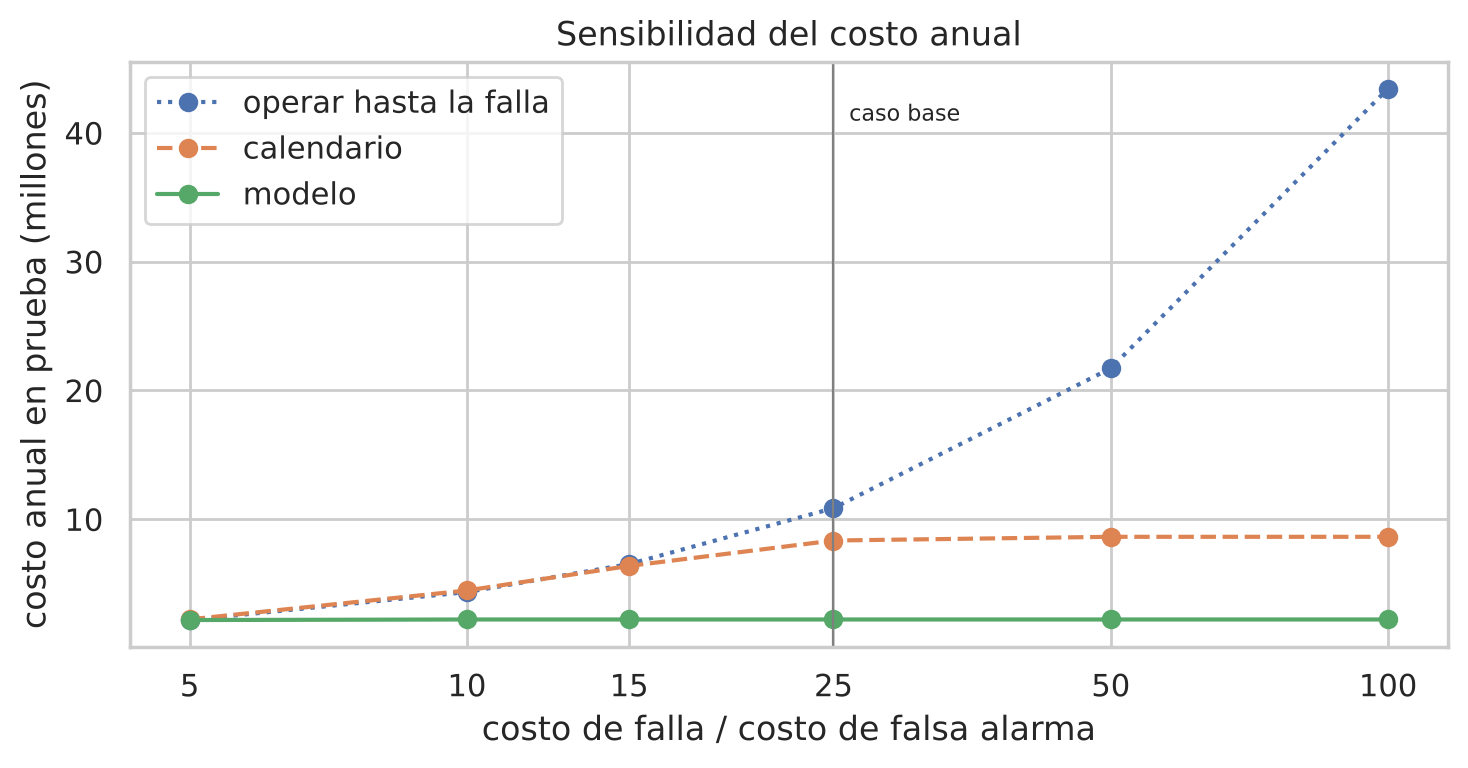

In [11]:
RATIOS = [5, 10, 15, 25, 50, 100]
cal_grid = np.arange(240, 24 * 365, 48)
sens_rows = []
t0 = time.time()
for r in RATIOS:
    c = {'failure': r * 600, 'hit': 3000, 'false_alarm': 600}
    thr_r, _ = plateau_threshold(sim_val.sweep(pb_final, threshold_grid(pb_final), costs=c))
    T_r = {comp: int(best_calendar(maint, failures, comp, CAL_START, CAL_END, grid=cal_grid, costs=c)[0]['T_h']) for comp in COMPS}
    m_te = sim_te.run(pb_te, thr_r, costs=c)
    cal_r = calendar_policy(test_meta.datetime.min(), test_meta.datetime.max() + pd.Timedelta(hours=24), T=T_r, costs=c)
    days = sim_te.n_hours / 24
    rtf = len(sim_te.fail) * c['failure']
    sens_rows.append({'razón falla/falsa alarma': r, 'costo falla': c['failure'], 'umbral (val)': thr_r,
                      'T calendario medio (días)': np.mean(list(T_r.values())) / 24,
                      'operar hasta la falla (M/año)': rtf * 365 / days / 1e6,
                      'calendario (M/año)': cal_r.cost.sum() * 365 / days / 1e6,
                      'modelo (M/año)': m_te['cost'] * 365 / days / 1e6,
                      'falsas alarmas/semana': m_te['false_alarms'] / (days / 7), 'fallas evitadas (%)': 100 * m_te['failures_avoided'] / m_te['failures']})
sens = pd.DataFrame(sens_rows).set_index('razón falla/falsa alarma')
print(f'sensitivity done in {time.time() - t0:.0f}s')
display(sens.round(3))
sens.to_csv(os.path.join(OUT_DIR, 'week3_sensitivity.csv'))

fig, ax = plt.subplots(figsize=(7.5, 4))
for col, st in [('operar hasta la falla (M/año)', ':'), ('calendario (M/año)', '--'), ('modelo (M/año)', '-')]:
    ax.plot(sens.index, sens[col], marker='o', ls=st, label=col.replace(' (M/año)', ''))
ax.axvline(25, color='grey', lw=0.8); ax.text(26, ax.get_ylim()[1] * 0.9, 'caso base', fontsize=8)
ax.set_xscale('log'); ax.set_xticks(RATIOS); ax.set_xticklabels(RATIOS)
ax.set_xlabel('costo de falla / costo de falsa alarma'); ax.set_ylabel('costo anual en prueba (millones)'); ax.set_title('Sensibilidad del costo anual'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'sensitivity.png'), dpi=160); plt.show()

### Revisión a mano de una máquina en prueba

Probabilidad calibrada del modelo final junto con el umbral, las alertas emitidas, los errores y las fallas reales (recomendación 3 del enunciado).

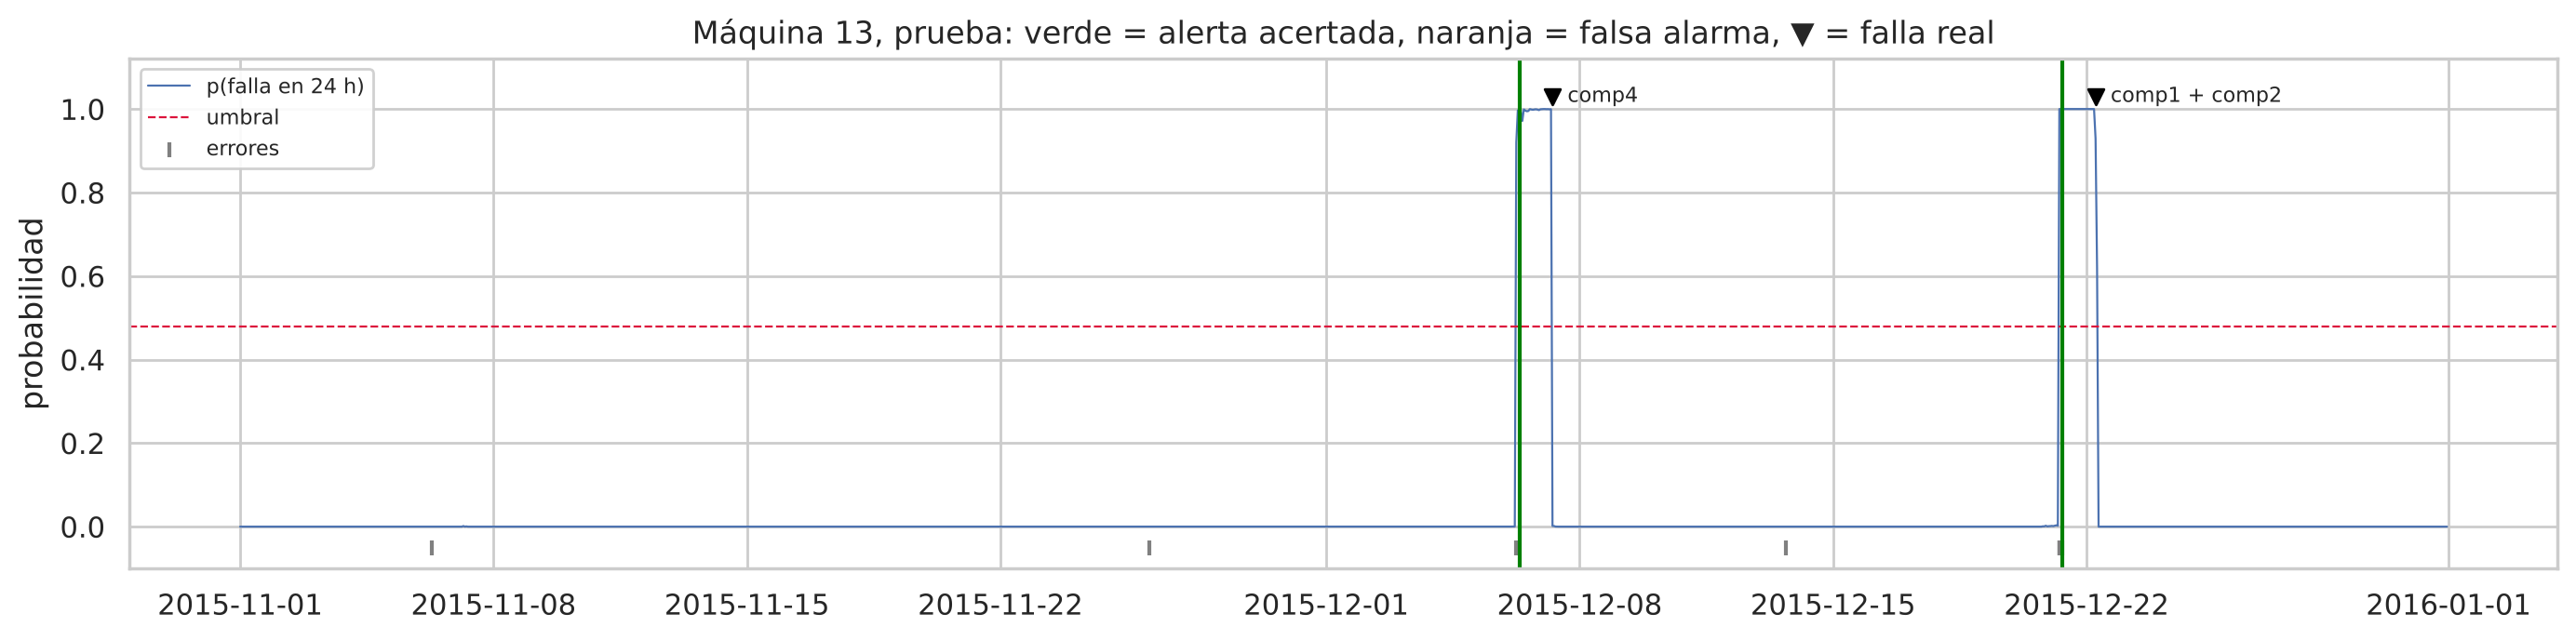

In [12]:
fail_te = sim_te.fail
mid = fail_te.machineID.value_counts().index[0]
sel = (test_meta.machineID == mid).values
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.plot(test_meta.datetime[sel], pb_te[sel], lw=0.8, label='p(falla en 24 h)')
ax.axhline(D['threshold'], color='crimson', ls='--', lw=0.8, label='umbral')
for r_, hit, _ in te_policy['_alerts']:
    if test_meta.machineID.iloc[r_] == mid:
        ax.axvline(test_meta.datetime.iloc[r_], color='green' if hit else 'orange', lw=1.5)
for t_, g in fail_te[fail_te.machineID == mid].groupby('datetime'):
    ax.scatter(t_, 1.03, marker='v', color='black')
    ax.text(t_ + pd.Timedelta(hours=10), 1.03, ' + '.join(sorted(g.failure)), fontsize=8, ha='left', va='center')
e = errors[(errors.machineID == mid) & errors.datetime.between(test_meta.datetime.min(), test_meta.datetime.max())]
ax.scatter(e.datetime, np.full(len(e), -0.05), marker='|', color='grey', label='errores')
ax.set_ylim(-0.1, 1.12); ax.set_title(f'Máquina {mid}, prueba: verde = alerta acertada, naranja = falsa alarma, ▼ = falla real')
ax.set_ylabel('probabilidad'); ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'machine_check_test.png'), dpi=160); plt.show()

### Figura de resumen de la semana 2 (solo validación)

Para el reporte final: PR-AUC de validación por arquitectura y longitud de ventana, a partir de las predicciones cacheadas de la semana 2 (`runs/week2/*.npz`). No usa prueba.

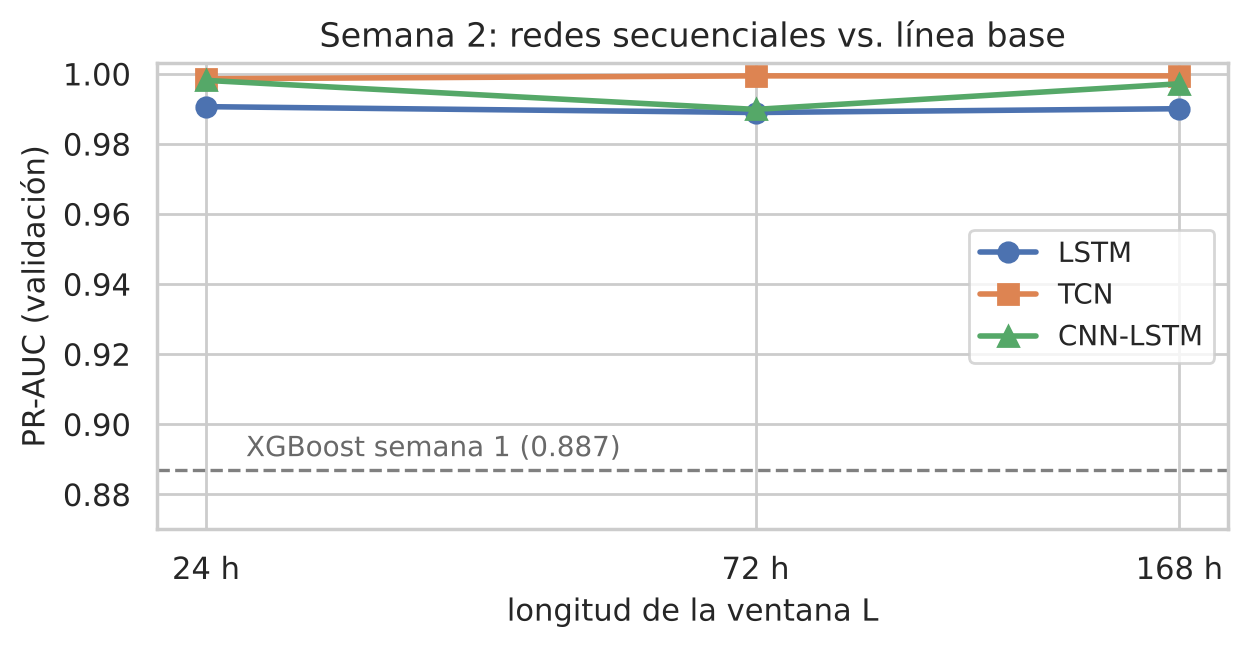

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for arch, mk in [('LSTM', 'o'), ('TCN', 's'), ('CNN-LSTM', '^')]:
    vals = [average_precision_score(VA.yb, np.load(os.path.join('runs', 'week2', f'{arch}_L{Lw}.npz'), allow_pickle=True)['pb']) for Lw in (24, 72, 168)]
    ax.plot([24, 72, 168], vals, marker=mk, lw=2, ms=7, label=arch)
xgb_ap = average_precision_score(VA.yb, baseline['XGBoost (semana 1)'][0]) if baseline else 0.8869   # value reported by week 1
ax.axhline(xgb_ap, color='grey', ls='--', lw=1.2); ax.text(26, xgb_ap + 0.004, f'XGBoost semana 1 ({xgb_ap:.3f})', fontsize=10, color='dimgrey')
ax.set_xscale('log'); ax.set_xticks([24, 72, 168]); ax.set_xticklabels(['24 h', '72 h', '168 h']); ax.minorticks_off()
ax.set_ylim(0.87, 1.003); ax.set_xlabel('longitud de la ventana L', fontsize=11); ax.set_ylabel('PR-AUC (validación)', fontsize=11)
ax.set_title('Semana 2: redes secuenciales vs. línea base', fontsize=12); ax.legend(loc='center right', fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'week2_effect_L_es.png'), dpi=200); plt.show()

In [14]:
# Summary tables for the report
res = pd.DataFrame(results).set_index('model')
res.to_csv(os.path.join(OUT_DIR, 'week3_validation_comparison.csv'))
calibration.to_csv(os.path.join(OUT_DIR, 'week3_calibration_validation.csv'))
share.to_csv(os.path.join(OUT_DIR, 'week3_ig_channel_share.csv'))
test_metrics.to_csv(os.path.join(OUT_DIR, 'week3_test_metrics.csv'))
summary = {'final_model': FINAL, 'temperature': T_SCALE, 'threshold': THRESHOLD, 'calendar_T_days': {k: v / 24 for k, v in cal_T.items()},
           'val': {k: v for k, v in val_policy.items() if not k.startswith('_')},
           'test': {k: v for k, v in te_policy.items() if not k.startswith('_')}, 'test_component_correct_%': 100 * comp_ok, 'test_bootstrap_ci': ci.round(3).to_dict(orient='index'),
           'minutes_trained': minutes}
with open(os.path.join(OUT_DIR, 'week3_summary.json'), 'w') as f:
    json.dump(summary, f, indent=1, default=float)
print(json.dumps(summary, indent=1, default=float))

{
 "final_model": "TCN (semana 2)",
 "temperature": 1.1542251366756358,
 "threshold": 0.48000000000000004,
 "calendar_T_days": {
  "comp1": 44.0,
  "comp2": 59.0,
  "comp3": 97.0,
  "comp4": 69.0
 },
 "val": {
  "threshold": 0.48000000000000004,
  "alerts": 115,
  "false_alarms": 3,
  "failures": 118,
  "failures_avoided": 118,
  "failures_missed": 0,
  "cost": 355800,
  "lead_mean_h": 21.43220338983051,
  "days": 60.0
 },
 "test": {
  "threshold": 0.48000000000000004,
  "alerts": 126,
  "false_alarms": 12,
  "failures": 121,
  "failures_avoided": 121,
  "failures_missed": 0,
  "cost": 370200,
  "lead_mean_h": 21.016528925619834,
  "days": 61.0
 },
 "test_component_correct_%": 100.0,
 "test_bootstrap_ci": {
  "Operar hasta la falla": {
   "costo anual (M)": 10.841,
   "IC 95 % inf.": 9.245,
   "IC 95 % sup.": 12.476
  },
  "Reemplazo por calendario": {
   "costo anual (M)": 8.356,
   "IC 95 % inf.": 7.216,
   "IC 95 % sup.": 9.568
  },
  "Alertas del modelo": {
   "costo anual (M)": 2.